# Линейные модели с нуля: сравнение с sklearn

Ноутбук проверяет собственные `LinearRegression` и `LogisticRegression`
(пакет `linear_models`) на реальных и синтетических данных. Каждая модель
обучается и проверяется на **тех же данных**, что и её аналог из `sklearn`.

Разделы:
1. Данные
2. Линейная регрессия: `analytic` и `gradient` против `LinearRegression` и `Ridge`
3. Логистическая регрессия против `sklearn.linear_model.LogisticRegression`
4. Режимы: без штрафа, L1, L2, с `intercept` и без
5. Сходимость: `loss_history_` и `learning_rate`
6. Выводы и объяснение расхождений

In [1]:
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import sklearn
from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression
from sklearn.linear_model import Ridge as SkRidge
from sklearn.linear_model import Lasso as SkLasso
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from linear_models.linear_regression import LinearRegression
from linear_models.logistic_regression import LogisticRegression

SEED = 42
np.set_printoptions(precision=6, suppress=True)

print("python      :", sys.version.split()[0])
print("numpy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib  :", matplotlib.__version__)
print("свои классы :", LinearRegression.__name__, LogisticRegression.__name__)
print("sklearn     :", SkLinearRegression.__name__, SkRidge.__name__, SkLogisticRegression.__name__)

python      : 3.12.7
numpy       : 2.5.3
scikit-learn: 1.9.1
matplotlib  : 3.11.2
свои классы : LinearRegression LogisticRegression
sklearn     : LinearRegression Ridge LogisticRegression


## 1. Данные

Четыре набора: для регрессии синтетика с известными весами и `load_diabetes`,
для классификации синтетика и `load_breast_cancer`.

- Одно разбиение train/test на набор: `test_size=0.25`, `random_state=SEED`
  (для классификации со `stratify=y`, чтобы доли классов совпадали).
- Признаки стандартизируются: **среднее и стандартное отклонение считаются
  только по train**, к test применяется то же преобразование.
- Наши модели и модели `sklearn` получают **одни и те же** массивы.
- Масштабирование нужно из-за градиентного спуска с фиксированным
  `learning_rate`: на сырых признаках `load_breast_cancer` он не успевает
  сойтись (это показано в разделе про сходимость).

In [2]:
TEST_SIZE = 0.25


def split_and_scale(X, y, stratify=None):
    """Одно разбиение train/test и стандартизация по train."""
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=SEED, stratify=stratify
    )
    scaler = StandardScaler().fit(X_train)
    return {
        "X_train": scaler.transform(X_train),
        "X_test": scaler.transform(X_test),
        "y_train": y_train,
        "y_test": y_test,
    }


rng = np.random.default_rng(SEED)
n, d = 300, 3
W_TRUE = np.array([2.0, -1.0, 0.5])
B_TRUE = 1.0
X_syn = rng.standard_normal((n, d))
z_syn = X_syn @ W_TRUE + B_TRUE

y_syn_reg = z_syn + 0.5 * rng.standard_normal(n)
y_syn_clf = (rng.random(n) < 1 / (1 + np.exp(-z_syn))).astype(int)

X_dia, y_dia = load_diabetes(return_X_y=True)
X_bc, y_bc = load_breast_cancer(return_X_y=True)

REG_DATA = {
    "synthetic": split_and_scale(X_syn, y_syn_reg),
    "diabetes": split_and_scale(X_dia, y_dia),
}
CLF_DATA = {
    "synthetic": split_and_scale(X_syn, y_syn_clf, stratify=y_syn_clf),
    "breast_cancer": split_and_scale(X_bc, y_bc, stratify=y_bc),
}

for group in (REG_DATA, CLF_DATA):
    for name, s in group.items():
        assert s["X_train"].shape[0] == s["y_train"].shape[0]
        assert s["X_test"].shape[0] == s["y_test"].shape[0]
        assert np.allclose(s["X_train"].mean(axis=0), 0.0, atol=1e-10)
        assert np.allclose(s["X_train"].std(axis=0), 1.0)

for title, group in (("регрессия", REG_DATA), ("классификация", CLF_DATA)):
    print(title)
    for name, s in group.items():
        print(
            f"  {name:14s} train {s['X_train'].shape}, test {s['X_test'].shape}",
            f"| y_train mean {s['y_train'].mean():.4f}, y_test mean {s['y_test'].mean():.4f}",
        )
print("W_TRUE =", W_TRUE, " B_TRUE =", B_TRUE)
print("classes in synthetic y:", np.bincount(y_syn_clf))
print("synthetic X_train mean:", CLF_DATA["synthetic"]["X_train"].mean(axis=0))

регрессия
  synthetic      train (225, 3), test (75, 3) | y_train mean 0.9254, y_test mean 1.1284
  diabetes       train (331, 10), test (111, 10) | y_train mean 154.3444, y_test mean 145.5405
классификация
  synthetic      train (225, 3), test (75, 3) | y_train mean 0.6267, y_test mean 0.6267
  breast_cancer  train (426, 30), test (143, 30) | y_train mean 0.6268, y_test mean 0.6294
W_TRUE = [ 2.  -1.   0.5]  B_TRUE = 1.0
classes in synthetic y: [112 188]
synthetic X_train mean: [0. 0. 0.]


## 2. Линейная регрессия

### 2.1. `solver="analytic"` без штрафа против `sklearn.linear_model.LinearRegression`

Обе модели решают одну задачу наименьших квадратов точным методом, поэтому
ожидается совпадение до ошибок округления (порядка `1e-13` и меньше), а не
просто «разумная близость». Сравниваются коэффициенты, `intercept`,
предсказания на test и метрики на test (MSE и R²), посчитанные одной и той же
функцией `sklearn.metrics` для обеих моделей.

In [3]:
def max_abs_diff(a, b):
    """Наибольшее по модулю отличие двух массивов."""
    return float(np.max(np.abs(np.asarray(a) - np.asarray(b))))


def report_regression(title, own, sk, data):
    """Обучает обе модели на train и печатает сравнение на одних и тех же данных."""
    own.fit(data["X_train"], data["y_train"])
    sk.fit(data["X_train"], data["y_train"])
    pred_own = own.predict(data["X_test"])
    pred_sk = sk.predict(data["X_test"])
    y_test = data["y_test"]
    print(title)
    print(f"  макс |разность коэффициентов| : {max_abs_diff(own.coef_, sk.coef_):.2e}")
    print(f"  |разность intercept|          : {abs(own.intercept_ - sk.intercept_):.2e}")
    print(f"  макс |разность предсказаний|  : {max_abs_diff(pred_own, pred_sk):.2e}")
    print(f"  test MSE  свой / sklearn      : {mean_squared_error(y_test, pred_own):.6f} / {mean_squared_error(y_test, pred_sk):.6f}")
    print(f"  test R2   свой / sklearn      : {r2_score(y_test, pred_own):.6f} / {r2_score(y_test, pred_sk):.6f}")
    return own, sk

In [4]:
for name, data in REG_DATA.items():
    own, sk = report_regression(
        f"{name}: analytic vs LinearRegression",
        LinearRegression(solver="analytic"),
        SkLinearRegression(),
        data,
    )
    assert max_abs_diff(own.coef_, sk.coef_) < 1e-8
    assert abs(own.intercept_ - sk.intercept_) < 1e-8
    if name == "synthetic":
        print("  свои coef_:", own.coef_, " intercept_:", round(own.intercept_, 6), " (истина", W_TRUE, B_TRUE, ")")

synthetic: analytic vs LinearRegression
  макс |разность коэффициентов| : 8.88e-16
  |разность intercept|          : 0.00e+00
  макс |разность предсказаний|  : 3.55e-15
  test MSE  свой / sklearn      : 0.260529 / 0.260529
  test R2   свой / sklearn      : 0.943110 / 0.943110
  свои coef_: [ 2.10308  -0.926902  0.485461]  intercept_: 0.925435  (истина [ 2.  -1.   0.5] 1.0 )
diabetes: analytic vs LinearRegression
  макс |разность коэффициентов| : 3.55e-14
  |разность intercept|          : 0.00e+00
  макс |разность предсказаний|  : 1.14e-13
  test MSE  свой / sklearn      : 2848.310651 / 2848.310651
  test R2   свой / sklearn      : 0.484906 / 0.484906


### 2.2. `solver="gradient"` без штрафа против `sklearn.linear_model.LinearRegression`

Параметры спуска: `learning_rate=0.4`, `max_iter=20000`, `tol=0.0`.

- `learning_rate=0.4` меньше границы устойчивости `2 / λ_max` (для `diabetes`
  она равна `0.510`, для синтетики `1.823`), где `λ_max` это наибольшее
  собственное число матрицы `XᵀX / n`.
- `tol=0.0` выключает раннюю остановку, чтобы сравнивать именно точность
  оптимизации, а не критерий остановки (его разберём в разделе про сходимость).
- `max_iter=20000` выбрано по замеру: на `diabetes` самое медленное направление
  затухает с множителем около `1 − 0.4 · 0.0094 ≈ 0.9962` за шаг, этого хватает
  для точности порядка `1e-12`.

Кроме сравнения с `sklearn` печатается значение цели `J` у `analytic` и
`gradient`: у точного решения и у сошедшегося спуска оно должно совпасть.

In [5]:
GRAD_PARAMS = {"solver": "gradient", "learning_rate": 0.4, "max_iter": 20000, "tol": 0.0}

for name, data in REG_DATA.items():
    own, sk = report_regression(
        f"{name}: gradient vs LinearRegression",
        LinearRegression(**GRAD_PARAMS),
        SkLinearRegression(),
        data,
    )
    ana = LinearRegression(solver="analytic").fit(data["X_train"], data["y_train"])
    print(f"  n_iter_: {own.n_iter_}")
    print(f"  J (цель) analytic / gradient  : {ana.loss_history_[-1]:.6f} / {own.loss_history_[-1]:.6f}")
    assert own.n_iter_ == GRAD_PARAMS["max_iter"]
    assert max_abs_diff(own.coef_, sk.coef_) < 1e-8
    assert abs(own.intercept_ - sk.intercept_) < 1e-8

synthetic: gradient vs LinearRegression
  макс |разность коэффициентов| : 1.33e-15
  |разность intercept|          : 0.00e+00
  макс |разность предсказаний|  : 4.44e-15
  test MSE  свой / sklearn      : 0.260529 / 0.260529
  test R2   свой / sklearn      : 0.943110 / 0.943110
  n_iter_: 20000
  J (цель) analytic / gradient  : 0.115316 / 0.115316
diabetes: gradient vs LinearRegression
  макс |разность коэффициентов| : 6.39e-13
  |разность intercept|          : 2.84e-14
  макс |разность предсказаний|  : 3.84e-13
  test MSE  свой / sklearn      : 2848.310651 / 2848.310651
  test R2   свой / sklearn      : 0.484906 / 0.484906
  n_iter_: 20000
  J (цель) analytic / gradient  : 1453.628882 / 1453.628882


### 2.3. L2: `analytic` и `gradient` против `sklearn.linear_model.Ridge`

Цели записаны по-разному. Наша: `(1/2n) · Σ (zᵢ − yᵢ)² + alpha · ½ ‖w‖²`.
У `Ridge`: `Σ (zᵢ − yᵢ)² + α_sk · ‖w‖²`. Если умножить нашу цель на `2n`,
получится `Σ (zᵢ − yᵢ)² + n · alpha · ‖w‖²`, поэтому **`α_sk = n · alpha`**,
где `n` это число объектов в train. Свободный член не штрафуется ни у нас, ни у
`Ridge`.

В таблице: наибольшая по модулю разность коэффициентов, `intercept` и предсказаний
на test, затем MSE на test для нашей модели и `sklearn`. Последняя строка
показывает, что бывает, если забыть множитель `n`.

Для L2 граница устойчивости спуска сдвигается: `learning_rate < 2 / (λ_max + alpha)`.
Для `diabetes` при `alpha = 0.5` она равна `0.4526`, наш `learning_rate = 0.4` ниже.

In [6]:
def regression_row(own, sk, data):
    """Обучает обе модели на train и возвращает числа для одной строки сравнения."""
    own.fit(data["X_train"], data["y_train"])
    sk.fit(data["X_train"], data["y_train"])
    pred_own = own.predict(data["X_test"])
    pred_sk = sk.predict(data["X_test"])
    y_test = data["y_test"]
    return {
        "coef": max_abs_diff(own.coef_, sk.coef_),
        "intercept": abs(own.intercept_ - sk.intercept_),
        "pred": max_abs_diff(pred_own, pred_sk),
        "mse_own": mean_squared_error(y_test, pred_own),
        "mse_sk": mean_squared_error(y_test, pred_sk),
    }

In [7]:
ALPHAS = (0.1, 0.5)

print(f"{'набор':10s} {'alpha':>5s} {'solver':>9s} {'coef':>9s} {'intercept':>9s} {'pred':>9s}   test MSE свой / sklearn")
for name, data in REG_DATA.items():
    n_train = data["X_train"].shape[0]
    for alpha in ALPHAS:
        for solver_params in ({"solver": "analytic"}, GRAD_PARAMS):
            own = LinearRegression(penalty="l2", alpha=alpha, **solver_params)
            sk = SkRidge(alpha=n_train * alpha)
            row = regression_row(own, sk, data)
            print(
                f"{name:10s} {alpha:5.1f} {solver_params['solver']:>9s} "
                f"{row['coef']:9.2e} {row['intercept']:9.2e} {row['pred']:9.2e}"
                f"   {row['mse_own']:.6f} / {row['mse_sk']:.6f}"
            )
            assert row["coef"] < 1e-8 and row["intercept"] < 1e-8

data = REG_DATA["diabetes"]
wrong = regression_row(
    LinearRegression(penalty="l2", alpha=0.5, solver="analytic"), SkRidge(alpha=0.5), data
)
print(f"diabetes, alpha=0.5, Ridge(alpha=alpha) без множителя n: макс |разность коэффициентов| = {wrong['coef']:.3f}")

набор      alpha    solver      coef intercept      pred   test MSE свой / sklearn
synthetic    0.1  analytic  1.78e-15  0.00e+00  5.77e-15   0.293611 / 0.293611
synthetic    0.1  gradient  1.78e-15  0.00e+00  5.33e-15   0.293611 / 0.293611
synthetic    0.5  analytic  1.11e-15  0.00e+00  3.55e-15   0.788921 / 0.788921
synthetic    0.5  gradient  4.44e-16  1.11e-16  1.78e-15   0.788921 / 0.788921
diabetes     0.1  analytic  3.91e-14  0.00e+00  2.27e-13   2814.770710 / 2814.770710
diabetes     0.1  gradient  4.80e-14  2.84e-14  1.56e-13   2814.770710 / 2814.770710
diabetes     0.5  analytic  1.51e-14  0.00e+00  1.14e-13   2856.391620 / 2856.391620
diabetes     0.5  gradient  2.13e-14  2.84e-14  1.14e-13   2856.391620 / 2856.391620
diabetes, alpha=0.5, Ridge(alpha=alpha) без множителя n: макс |разность коэффициентов| = 36.318


## 3. Логистическая регрессия

Сравнение с `sklearn.linear_model.LogisticRegression`. Параметр `penalty` у
`sklearn` устарел (`FutureWarning` с версии 1.8, удаление в 1.10), поэтому
режимы задаются через `C` и `l1_ratio`:

| Режим | Наша модель | `sklearn` |
|---|---|---|
| без штрафа | `penalty=None` | `C=np.inf` |
| L2 | `penalty="l2", alpha=alpha` | `C=1/(n·alpha), l1_ratio=0` |
| L1 | `penalty="l1", alpha=alpha` | `C=1/(n·alpha), l1_ratio=1, solver="saga"` |

Здесь `n` это число объектов в train. Для L1 выбран `saga`: `liblinear`
штрафует свободный член, а у нас и у `saga` он не штрафуется; `lbfgs` L1 не
поддерживает. Параметры нашего спуска: `learning_rate=0.5`, `max_iter=20000`,
`tol=0.0`.

Для проверки точности добавлен независимый эталон: точное решение методом
Ньютона (не использует ни наши классы, ни `sklearn`).

### 3.1. Без штрафа, синтетика

Сравниваются коэффициенты, `intercept`, `predict_proba`, `predict` и accuracy
на test. Отдельно считается расстояние каждой модели до точного решения.

In [8]:
LOGIT_PARAMS = {"learning_rate": 0.5, "max_iter": 20000, "tol": 0.0}


def newton_reference(X, y, alpha=0.0, max_iter=100):
    """Точное решение (метод Ньютона) для логистической регрессии с L2-штрафом на w.

    Независимый эталон: не использует ни наши классы, ни sklearn.
    Возвращает (coef, intercept). Свободный член не штрафуется.
    """
    n, d = X.shape
    Xa = np.hstack([X, np.ones((n, 1))])
    theta = np.zeros(d + 1)
    R = np.diag([alpha] * d + [0.0])
    for _ in range(max_iter):
        p = 1 / (1 + np.exp(-(Xa @ theta)))
        grad = Xa.T @ (p - y) / n + R @ theta
        hess = (Xa.T * (p * (1 - p))) @ Xa / n + R
        step = np.linalg.solve(hess, grad)
        theta = theta - step
        if np.max(np.abs(step)) < 1e-15:
            break
    return theta[:d], theta[d]


def classification_row(own, sk, data):
    """Обучает обе модели на train и возвращает числа для одной строки сравнения."""
    own.fit(data["X_train"], data["y_train"])
    sk.fit(data["X_train"], data["y_train"])
    X_test, y_test = data["X_test"], data["y_test"]
    pred_own, pred_sk = own.predict(X_test), sk.predict(X_test)
    return {
        "coef": max_abs_diff(own.coef_, sk.coef_.ravel()),
        "intercept": abs(own.intercept_ - sk.intercept_[0]),
        "proba": max_abs_diff(own.predict_proba(X_test), sk.predict_proba(X_test)),
        "agree": np.mean(pred_own == pred_sk),
        "acc_own": np.mean(pred_own == y_test),
        "acc_sk": np.mean(pred_sk == y_test),
    }

In [9]:
data = CLF_DATA["synthetic"]
own = LogisticRegression(**LOGIT_PARAMS)
sk = SkLogisticRegression(C=np.inf, tol=1e-12, max_iter=10000)
row = classification_row(own, sk, data)
w_ref, b_ref = newton_reference(data["X_train"], data["y_train"])
dist_own = max(max_abs_diff(own.coef_, w_ref), abs(own.intercept_ - b_ref))
dist_sk = max(max_abs_diff(sk.coef_.ravel(), w_ref), abs(sk.intercept_[0] - b_ref))

print("synthetic, без штрафа: свой спуск vs LogisticRegression(C=np.inf)")
print(f"  макс |разность коэффициентов|      : {row['coef']:.2e}")
print(f"  |разность intercept|               : {row['intercept']:.2e}")
print(f"  макс |разность predict_proba|      : {row['proba']:.2e}")
print(f"  доля совпавших классов (predict)   : {row['agree']:.4f}")
print(f"  accuracy на test свой / sklearn    : {row['acc_own']:.4f} / {row['acc_sk']:.4f}")
print(f"  расстояние до точного решения (Ньютон), свой / sklearn: {dist_own:.2e} / {dist_sk:.2e}")
print("  свои coef_:", own.coef_, " intercept_:", round(own.intercept_, 6))
print("  sklearn coef_:", sk.coef_.ravel(), " intercept_:", round(float(sk.intercept_[0]), 6))
print("  n_iter_ свой:", own.n_iter_, " sklearn:", sk.n_iter_)
assert row["coef"] < 1e-6 and row["intercept"] < 1e-6 and row["proba"] < 1e-6
assert row["agree"] == 1.0
assert dist_own < 1e-10

synthetic, без штрафа: свой спуск vs LogisticRegression(C=np.inf)
  макс |разность коэффициентов|      : 1.58e-08
  |разность intercept|               : 2.90e-09
  макс |разность predict_proba|      : 3.33e-09
  доля совпавших классов (predict)   : 1.0000
  accuracy на test свой / sklearn    : 0.7467 / 0.7467
  расстояние до точного решения (Ньютон), свой / sklearn: 8.88e-15 / 1.58e-08
  свои coef_: [ 2.008027 -0.959728  0.348675]  intercept_: 0.93366
  sklearn coef_: [ 2.008027 -0.959728  0.348675]  intercept_: 0.93366
  n_iter_ свой: 20000  sklearn: [10]


### 3.2. Без штрафа, `breast_cancer`: расхождение и его причина

Обучающая часть этого набора линейно разделима: после того как все объекты
классифицированы правильно, дальнейшее увеличение весов только уменьшает
лосс. У цели **нет конечного минимума**, поэтому результат зависит лишь от
того, когда остановился алгоритм. Это видно по таблицам ниже: норма весов
растёт и у нашего спуска (с числом итераций), и у `sklearn` (с ужесточением
`tol`), а точность на train доходит до `1.0`.

Поэтому коэффициенты здесь не сравниваются: их разность определяется
критерием остановки, а не качеством реализации. Сравниваются предсказания:
классы совпадают почти везде, точность на test близка. Вероятности
отличаются сильнее, потому что у `sklearn` веса огромные и вероятности
прижаты к 0 и 1.

Есть и побочный эффект: у нашего спуска точность на test **падает** с
ростом числа итераций (`0.9790` при 1000, `0.9441` при 100000). Это одно
разбиение и 143 объекта, поэтому это иллюстрация, а не доказательство.
Практический вывод: для разделимых данных нужна регуляризация (L2 и L1 ниже).

In [10]:
data = CLF_DATA["breast_cancer"]
X_train, y_train = data["X_train"], data["y_train"]
X_test, y_test = data["X_test"], data["y_test"]

print("breast_cancer, без штрафа")
print("наш спуск (learning_rate=0.5, tol=0.0): рост весов с числом итераций")
print(f"  {'max_iter':>8s} {'||w||':>8s} {'J':>10s} {'train acc':>10s} {'test acc':>9s}")
own_norms, own_losses = [], []
for max_iter in (1000, 5000, 20000, 100000):
    model = LogisticRegression(learning_rate=0.5, max_iter=max_iter, tol=0.0).fit(X_train, y_train)
    own_norms.append(np.linalg.norm(model.coef_))
    own_losses.append(model.loss_history_[-1])
    print(
        f"  {max_iter:8d} {own_norms[-1]:8.2f} {own_losses[-1]:10.3e} "
        f"{np.mean(model.predict(X_train) == y_train):10.4f} {np.mean(model.predict(X_test) == y_test):9.4f}"
    )

print("sklearn (C=np.inf): рост весов с ужесточением tol")
print(f"  {'tol':>8s} {'n_iter':>6s} {'||w||':>9s} {'train acc':>10s} {'test acc':>9s}")
sk_norms = []
for tol in (1e-4, 1e-8, 1e-12):
    sk_model = SkLogisticRegression(C=np.inf, tol=tol, max_iter=100000).fit(X_train, y_train)
    sk_norms.append(np.linalg.norm(sk_model.coef_))
    print(
        f"  {tol:8.0e} {sk_model.n_iter_[0]:6d} {sk_norms[-1]:9.2f} "
        f"{np.mean(sk_model.predict(X_train) == y_train):10.4f} {np.mean(sk_model.predict(X_test) == y_test):9.4f}"
    )

own = LogisticRegression(**LOGIT_PARAMS)
sk = SkLogisticRegression(C=np.inf, tol=1e-12, max_iter=100000)
row = classification_row(own, sk, data)
n_disagree = int(np.sum(own.predict(X_test) != sk.predict(X_test)))
print("итог на test: свой (max_iter=20000) vs sklearn (tol=1e-12)")
print(f"  макс |разность коэффициентов|  : {row['coef']:.1f}  (сравнивать коэффициенты нельзя)")
print(f"  макс |разность predict_proba|  : {row['proba']:.4f}")
print(f"  доля совпавших классов         : {row['agree']:.4f}  (не совпали {n_disagree} из {len(y_test)})")
print(f"  accuracy на test свой / sklearn: {row['acc_own']:.4f} / {row['acc_sk']:.4f}")
assert all(a < b for a, b in zip(own_norms, own_norms[1:]))
assert all(a > b for a, b in zip(own_losses, own_losses[1:]))
assert all(a < b for a, b in zip(sk_norms, sk_norms[1:]))
assert np.mean(sk.predict(X_train) == y_train) == 1.0
assert row["agree"] > 0.97

breast_cancer, без штрафа
наш спуск (learning_rate=0.5, tol=0.0): рост весов с числом итераций
  max_iter    ||w||          J  train acc  test acc
      1000     4.80  4.702e-02     0.9883    0.9790
      5000     8.07  3.752e-02     0.9883    0.9720
     20000    16.15  2.523e-02     0.9953    0.9720
    100000    38.93  9.966e-03     1.0000    0.9441
sklearn (C=np.inf): рост весов с ужесточением tol
       tol n_iter     ||w||  train acc  test acc
     1e-04     37    451.56     1.0000    0.9580
     1e-08     51   1214.47     1.0000    0.9580
     1e-12     65   2057.29     1.0000    0.9580
итог на test: свой (max_iter=20000) vs sklearn (tol=1e-12)
  макс |разность коэффициентов|  : 1086.7  (сравнивать коэффициенты нельзя)
  макс |разность predict_proba|  : 0.7504
  доля совпавших классов         : 0.9860  (не совпали 2 из 143)
  accuracy на test свой / sklearn: 0.9720 / 0.9580


### 3.3. L2: наш `penalty="l2"` против `LogisticRegression(C=..., l1_ratio=0)`

Цель `sklearn` при `l1_ratio=0`: `C · Σ ℓᵢ + ½‖w‖²`. Наша: `(1/n) · Σ ℓᵢ + alpha · ½‖w‖²`.
Если разделить цель `sklearn` на `C · n`, штраф превращается в
`(1/(C·n)) · ½‖w‖²`, поэтому **`alpha = 1/(C·n)`, то есть `C = 1/(n·alpha)`**,
где `n` это число объектов в train. Свободный член не штрафуется ни у нас,
ни у `lbfgs`.

В таблице: разности коэффициентов, `intercept` и `predict_proba` (наша модель
против `sklearn`), доля совпавших классов, accuracy на test, а также расстояние
каждой модели до точного решения (метод Ньютона с тем же штрафом). Для L2
граница устойчивости спуска ниже, чем без штрафа (примерно `0.59` для
`breast_cancer` при `alpha=0.1`), наш `learning_rate=0.5` под ней.

In [11]:
ALPHAS_CLF = (0.01, 0.1)

print(f"{'набор':14s} {'alpha':>5s} {'C':>8s} {'coef':>9s} {'intercept':>9s} {'proba':>9s} {'agree':>6s}   accuracy свой / sklearn   до эталона свой / sklearn")
for name, data in CLF_DATA.items():
    n_train = data["X_train"].shape[0]
    for alpha in ALPHAS_CLF:
        C = 1 / (n_train * alpha)
        own = LogisticRegression(penalty="l2", alpha=alpha, **LOGIT_PARAMS)
        sk = SkLogisticRegression(C=C, l1_ratio=0, tol=1e-12, max_iter=10000)
        row = classification_row(own, sk, data)
        w_ref, b_ref = newton_reference(data["X_train"], data["y_train"], alpha=alpha)
        dist_own = max(max_abs_diff(own.coef_, w_ref), abs(own.intercept_ - b_ref))
        dist_sk = max(max_abs_diff(sk.coef_.ravel(), w_ref), abs(sk.intercept_[0] - b_ref))
        print(
            f"{name:14s} {alpha:5.2f} {C:8.4f} {row['coef']:9.2e} {row['intercept']:9.2e} "
            f"{row['proba']:9.2e} {row['agree']:6.3f}   {row['acc_own']:.4f} / {row['acc_sk']:.4f}"
            f"         {dist_own:.1e} / {dist_sk:.1e}"
        )
        assert row["coef"] < 1e-5 and row["intercept"] < 1e-5 and row["proba"] < 1e-5
        assert row["agree"] == 1.0
        assert dist_own < 1e-9

набор          alpha        C      coef intercept     proba  agree   accuracy свой / sklearn   до эталона свой / sklearn
synthetic       0.01   0.4444  1.37e-09  1.00e-09  4.10e-10  1.000   0.7600 / 0.7600         3.3e-15 / 1.4e-09
synthetic       0.10   0.0444  4.23e-11  8.53e-11  4.67e-11  1.000   0.7733 / 0.7733         6.7e-16 / 8.5e-11
breast_cancer   0.01   0.2347  2.60e-07  9.01e-08  1.51e-07  1.000   0.9860 / 0.9860         1.2e-14 / 2.6e-07
breast_cancer   0.10   0.0235  1.84e-08  9.92e-09  2.08e-08  1.000   0.9510 / 0.9510         1.7e-15 / 1.8e-08


### 3.4. L1: наш `penalty="l1"` против `LogisticRegression(C=..., l1_ratio=1, solver="saga")`

Соответствие параметров то же, что и для L2: `C = 1/(n·alpha)` (штраф `‖w‖₁`
делится на `C·n`). Решатель `saga`, потому что `liblinear` штрафует свободный
член, а `lbfgs` L1 не поддерживает.

Столбцы таблицы:

- `dJ` : наша цель минус цель `sklearn` на train (цель с L1: средний лосс +
  `alpha·Σ|w|`); не отрицательна, потому что `saga` ближе к минимуму;
- `coef_nz` : наибольшая разность коэффициентов по признакам, **ненулевым** у `sklearn`;
- `w_zero` : наибольший `|w|` нашей модели по признакам, равным **нулю** у
  `sklearn` (у нас они не нули);
- `lr*alpha` : масштаб колебаний субградиентного шага;
- `nnz_sk` : число ненулевых весов у `sklearn` из общего числа признаков.

Вес `w_j = 0` оптимален, если `|g_j| ≤ alpha`. `saga` обнуляет такие веса
проксимальным шагом, поэтому нули у него точные. Наш субградиентный спуск с
постоянным шагом колеблется около нуля с размахом порядка `lr·alpha` и
точного нуля не даёт. Это известное ограничение метода (описано в README):
уменьшение `learning_rate` сжимает колебания, но замедляет спуск; убывающий шаг
или проксимальный метод решили бы вопрос, но выходят за рамки задания.

In [12]:
def l1_objective(coef, intercept, X, y, alpha):
    """Цель с L1: mean(логлосс) + alpha * sum|w| (свободный член не штрафуется)."""
    z = X @ coef + intercept
    return np.mean(np.logaddexp(0, z) - y * z) + alpha * np.sum(np.abs(coef))


ALPHAS_L1 = (0.01, 0.05)
L1_RUNS = (
    {"learning_rate": 0.5, "max_iter": 20000, "tol": 0.0},
    {"learning_rate": 0.1, "max_iter": 50000, "tol": 0.0},
)

print(f"{'набор':14s} {'alpha':>5s} {'lr':>4s} {'dJ':>10s} {'coef_nz':>9s} {'w_zero':>7s} {'lr*alpha':>8s} {'nnz_sk':>6s} {'agree':>6s}   accuracy свой / sklearn")
for name, data in CLF_DATA.items():
    X_train, y_train = data["X_train"], data["y_train"]
    n_train, d = X_train.shape
    for alpha in ALPHAS_L1:
        for params in L1_RUNS:
            own = LogisticRegression(penalty="l1", alpha=alpha, **params)
            sk = SkLogisticRegression(C=1 / (n_train * alpha), l1_ratio=1, solver="saga", tol=1e-10, max_iter=200000)
            row = classification_row(own, sk, data)
            w_sk = sk.coef_.ravel()
            zero = w_sk == 0
            d_j = l1_objective(own.coef_, own.intercept_, X_train, y_train, alpha) - l1_objective(w_sk, sk.intercept_[0], X_train, y_train, alpha)
            coef_nz = max_abs_diff(own.coef_[~zero], w_sk[~zero])
            w_zero = np.max(np.abs(own.coef_[zero])) if zero.any() else 0.0
            step = params["learning_rate"] * alpha
            print(
                f"{name:14s} {alpha:5.2f} {params['learning_rate']:4.1f} {d_j:10.2e} {coef_nz:9.2e} {w_zero:7.4f} "
                f"{step:8.4f} {int((~zero).sum()):3d}/{d:<2d} {row['agree']:6.3f}   {row['acc_own']:.4f} / {row['acc_sk']:.4f}"
            )
            assert d_j > -1e-9
            assert w_zero < 3 * step
            assert row["agree"] > 0.97
            if name == "synthetic" and alpha == 0.01:
                assert coef_nz < 1e-6

набор          alpha   lr         dJ   coef_nz  w_zero lr*alpha nnz_sk  agree   accuracy свой / sklearn
synthetic       0.01  0.5   5.55e-17  9.19e-11  0.0000   0.0050   3/3   1.000   0.7467 / 0.7467
synthetic       0.01  0.1   0.00e+00  3.71e-10  0.0000   0.0010   3/3   1.000   0.7467 / 0.7467
synthetic       0.05  0.5   3.46e-04  2.23e-03  0.0268   0.0250   2/3   1.000   0.7333 / 0.7333
synthetic       0.05  0.1   1.21e-05  3.75e-04  0.0011   0.0050   2/3   1.000   0.7333 / 0.7333
breast_cancer   0.01  0.5   3.08e-04  2.06e-02  0.0068   0.0050   9/30  1.000   0.9650 / 0.9650
breast_cancer   0.01  0.1   5.44e-05  9.01e-03  0.0019   0.0010   9/30  1.000   0.9650 / 0.9650
breast_cancer   0.05  0.5   7.68e-03  1.63e-01  0.0386   0.0250   4/30  1.000   0.9441 / 0.9441
breast_cancer   0.05  0.1   1.41e-03  3.39e-02  0.0090   0.0050   4/30  1.000   0.9441 / 0.9441


## 4. Режимы: штраф и `fit_intercept`

Секция закрывает пункт задания «без регуляризации, L1, L2, с `intercept` и без него». Без штрафа и с L2 всё уже проверено в разделах 2 и 3, поэтому здесь два дополнения: L1 для регрессии (4.1) и сводная матрица «модель × штраф × `fit_intercept`» (4.2).

### 4.1 Линейная регрессия с L1 против `Lasso`

`Lasso` минимизирует `1/(2n)·‖y − Xw − b‖² + α·‖w‖₁`. Это в точности наша цель, поэтому `alpha_sklearn = alpha` (без множителя `n`, в отличие от `Ridge`, где `alpha_sklearn = n·alpha`).

Ожидание то же, что в 3.4. Если у `Lasso` все коэффициенты ненулевые, решения совпадают до ошибок округления. Если часть коэффициентов `Lasso` обнуляет точно, наш субградиентный спуск колеблется около нуля с размахом порядка `learning_rate·alpha` и до нуля не доходит.

Столбцы: `dJ` — разность цели (наша минус sklearn, должна быть ≥ 0), `coef` — максимальная разность коэффициентов, `w_zero` — наибольший наш коэффициент там, где у `Lasso` ноль, `lr*alpha` — размер шага штрафа, `nnz_sk` — число ненулевых коэффициентов у `Lasso`.

In [13]:
def lasso_objective(coef, intercept, X, y, alpha):
    """Цель L1-регрессии: 1/(2n)·Σ(z−y)² + alpha·Σ|w| (свободный член не штрафуется)."""
    n = X.shape[0]
    return np.sum((X @ coef + intercept - y) ** 2) / (2 * n) + alpha * np.sum(np.abs(coef))


ALPHAS_LASSO = (0.01, 0.1)
L1_REG_RUNS = (
    {"learning_rate": 0.4, "max_iter": 20000, "tol": 0.0},
    {"learning_rate": 0.1, "max_iter": 50000, "tol": 0.0},
)

print(f"{'набор':10s} {'alpha':>5s} {'lr':>4s} {'dJ':>10s} {'coef':>9s} {'w_zero':>7s} {'lr*alpha':>8s} {'nnz_sk':>6s}   test MSE свой / sklearn")
for name, data in REG_DATA.items():
    X_train, y_train = data["X_train"], data["y_train"]
    d = X_train.shape[1]
    for alpha in ALPHAS_LASSO:
        for params in L1_REG_RUNS:
            own = LinearRegression(solver="gradient", penalty="l1", alpha=alpha, **params)
            sk = SkLasso(alpha=alpha, tol=1e-12, max_iter=1_000_000)
            row = regression_row(own, sk, data)
            zero = sk.coef_ == 0
            d_j = lasso_objective(own.coef_, own.intercept_, X_train, y_train, alpha) - lasso_objective(sk.coef_, sk.intercept_, X_train, y_train, alpha)
            w_zero = np.max(np.abs(own.coef_[zero])) if zero.any() else 0.0
            step = params["learning_rate"] * alpha
            print(
                f"{name:10s} {alpha:5.2f} {params['learning_rate']:4.1f} {d_j:10.2e} {row['coef']:9.2e} {w_zero:7.4f} "
                f"{step:8.4f} {int((~zero).sum()):3d}/{d:<2d}   {row['mse_own']:.6f} / {row['mse_sk']:.6f}"
            )
            assert d_j > -1e-9
            assert w_zero < 3 * step
            if not zero.any():
                assert row["coef"] < 1e-6 and row["intercept"] < 1e-8

набор      alpha   lr         dJ      coef  w_zero lr*alpha nnz_sk   test MSE свой / sklearn
synthetic   0.01  0.4   0.00e+00  2.04e-14  0.0000   0.0040   3/3    0.258113 / 0.258113
synthetic   0.01  0.1   0.00e+00  1.87e-14  0.0000   0.0010   3/3    0.258113 / 0.258113
synthetic   0.10  0.4   0.00e+00  1.69e-14  0.0000   0.0400   3/3    0.266538 / 0.266538
synthetic   0.10  0.1   0.00e+00  1.60e-14  0.0000   0.0100   3/3    0.266538 / 0.266538
diabetes    0.01  0.4   6.82e-13  2.20e-09  0.0000   0.0040  10/10   2847.190851 / 2847.190851
diabetes    0.01  0.1   4.55e-13  2.20e-09  0.0000   0.0010  10/10   2847.190851 / 2847.190851
diabetes    0.10  0.4   1.98e-03  3.74e-02  0.0046   0.0400   9/10   2838.570998 / 2839.014955
diabetes    0.10  0.1   5.26e-04  4.95e-03  0.0049   0.0100   9/10   2838.877170 / 2839.014955


### 4.2 Сводная матрица: штраф × `fit_intercept`

Для каждого сочетания «штраф × solver × `fit_intercept`» сравниваем свою модель с sklearn при одном и том же `alpha = 0.01`. Пересчёт параметров такой, как в разделах выше:

| Задача | Штраф | Параметр sklearn |
|---|---|---|
| регрессия | L2 | `Ridge(alpha = n·alpha)` |
| регрессия | L1 | `Lasso(alpha = alpha)` |
| логистика | L2 / L1 | `C = 1/(n·alpha)` |

При `fit_intercept=False` свободный член равен нулю у обеих моделей: `analytic` не центрирует данные, `gradient` не обновляет `b`. Проверка `own.intercept_ == 0.0` в ячейке это подтверждает.

Ожидание: во всех строках разность коэффициентов не больше 1e-6 (на практике 1e-8 и меньше), у логистики полностью совпадают предсказанные классы.

In [14]:
ALPHA_MATRIX = 0.01
REG_MODES = (
    # (подпись, kwargs своей модели, функция n_train -> sklearn-модель при fit_intercept)
    ("без штрафа, analytic", {"solver": "analytic"}, lambda n, fi: SkLinearRegression(fit_intercept=fi)),
    ("без штрафа, gradient", GRAD_PARAMS, lambda n, fi: SkLinearRegression(fit_intercept=fi)),
    ("L2, analytic", {"solver": "analytic", "penalty": "l2", "alpha": ALPHA_MATRIX},
     lambda n, fi: SkRidge(alpha=n * ALPHA_MATRIX, fit_intercept=fi)),
    ("L2, gradient", {**GRAD_PARAMS, "penalty": "l2", "alpha": ALPHA_MATRIX},
     lambda n, fi: SkRidge(alpha=n * ALPHA_MATRIX, fit_intercept=fi)),
    ("L1, gradient", {**GRAD_PARAMS, "penalty": "l1", "alpha": ALPHA_MATRIX},
     lambda n, fi: SkLasso(alpha=ALPHA_MATRIX, fit_intercept=fi, tol=1e-12, max_iter=1_000_000)),
)
CLF_MODES = (
    ("без штрафа", {},
     lambda n, fi: SkLogisticRegression(C=np.inf, fit_intercept=fi, tol=1e-12, max_iter=10000)),
    ("L2", {"penalty": "l2", "alpha": ALPHA_MATRIX},
     lambda n, fi: SkLogisticRegression(C=1 / (n * ALPHA_MATRIX), l1_ratio=0, fit_intercept=fi, tol=1e-12, max_iter=10000)),
    ("L1", {"penalty": "l1", "alpha": ALPHA_MATRIX},
     lambda n, fi: SkLogisticRegression(C=1 / (n * ALPHA_MATRIX), l1_ratio=1, solver="saga", random_state=SEED, fit_intercept=fi, tol=1e-10, max_iter=200000)),
)

data = REG_DATA["diabetes"]
n_train = data["X_train"].shape[0]
print(f"регрессия, diabetes, alpha={ALPHA_MATRIX}")
print(f"{'режим':22s} {'fit_int':>7s} {'coef':>9s} {'intercept':>9s} {'pred':>9s}   own.intercept_")
for label, params, make_sk in REG_MODES:
    for fit_intercept in (True, False):
        own = LinearRegression(fit_intercept=fit_intercept, **params)
        row = regression_row(own, make_sk(n_train, fit_intercept), data)
        print(
            f"{label:22s} {str(fit_intercept):>7s} {row['coef']:9.2e} {row['intercept']:9.2e} {row['pred']:9.2e}"
            f"   {own.intercept_:.4f}"
        )
        assert row["coef"] < 1e-6 and row["intercept"] < 1e-8
        if not fit_intercept:
            assert own.intercept_ == 0.0

data = CLF_DATA["synthetic"]
n_train = data["X_train"].shape[0]
print(f"\nклассификация, synthetic, alpha={ALPHA_MATRIX}")
print(f"{'режим':22s} {'fit_int':>7s} {'coef':>9s} {'intercept':>9s} {'proba':>9s} {'agree':>6s}   own.intercept_")
for label, params, make_sk in CLF_MODES:
    for fit_intercept in (True, False):
        own = LogisticRegression(fit_intercept=fit_intercept, **params, **LOGIT_PARAMS)
        row = classification_row(own, make_sk(n_train, fit_intercept), data)
        print(
            f"{label:22s} {str(fit_intercept):>7s} {row['coef']:9.2e} {row['intercept']:9.2e} {row['proba']:9.2e} {row['agree']:6.3f}"
            f"   {own.intercept_:.4f}"
        )
        assert row["coef"] < 1e-6 and row["intercept"] < 1e-6 and row["agree"] == 1.0
        if not fit_intercept:
            assert own.intercept_ == 0.0

регрессия, diabetes, alpha=0.01
режим                  fit_int      coef intercept      pred   own.intercept_
без штрафа, analytic      True  3.55e-14  0.00e+00  1.14e-13   154.3444
без штрафа, analytic     False  7.11e-14  0.00e+00  1.71e-13   0.0000
без штрафа, gradient      True  6.39e-13  2.84e-14  3.84e-13   154.3444
без штрафа, gradient     False  1.34e-12  0.00e+00  5.47e-13   0.0000
L2, analytic              True  2.70e-13  0.00e+00  2.27e-13   154.3444
L2, analytic             False  7.28e-13  0.00e+00  4.69e-13   0.0000
L2, gradient              True  6.75e-14  2.84e-14  1.71e-13   154.3444
L2, gradient             False  7.85e-13  0.00e+00  3.98e-13   0.0000
L1, gradient              True  2.20e-09  2.84e-14  6.47e-10   154.3444
L1, gradient             False  2.20e-09  0.00e+00  6.47e-10   0.0000

классификация, synthetic, alpha=0.01
режим                  fit_int      coef intercept     proba  agree   own.intercept_
без штрафа                True  1.58e-08  2.90e-09  3.33e

## 5. Сходимость градиентного спуска

### 5.1 Регрессия: кривые `loss_history_` и влияние `learning_rate`

Для линейной регрессии без штрафа цель `J` квадратична, её гессиан равен `XaᵀXa/n` (`Xa` — это `X` со столбцом единиц для `intercept`). Шаг спуска умножает ошибку по каждому собственному направлению с собственным значением `λ` на `(1 − lr·λ)`. Отсюда два вывода:

- спуск сходится, только если `|1 − lr·λ| < 1` для всех `λ`, то есть `lr < 2/λmax`;
- скорость определяет самое маленькое `λmin`: на больших `k` отношение соседних `J − J*` равно `(1 − lr·λmin)²`. Чем хуже обусловлена задача (`λmax/λmin` велико), тем медленнее спуск.

`loss_history_` пишется после каждого шага, поэтому `J(0)` в историю не входит. Слева: сходимость при трёх `lr` в логарифмической шкале; тонкие чёрные линии — предсказание формулы. Справа: поведение вокруг границы `2/λmax`.

diabetes: lambda_min = 0.00938, lambda_max = 3.91882, обусловленность = 418
граница устойчивости 2/lambda_max = 0.5104;  J* (analytic) = 1453.628882

   lr  J-J* (k=100)  J-J* (k=1000)  J-J* (k=3000)  наблюд. отношение    формула
 0.05    1.4436e+01     5.9446e+00     9.1055e-01         0.99906234 0.99906235
 0.20    1.0435e+01     3.5542e-01     1.9462e-04         0.99625203 0.99625203
 0.40    7.1625e+00     8.2584e-03     2.4413e-09         0.99251109 0.99251109

   lr lr*lambda_max  |1-lr*lambda_max|    J (k=1)    J (k=200)
 0.40        1.5675             0.5675     6254.3   1.4570e+03
 0.50        1.9594             0.9594     5407.6   1.4559e+03
 0.52        2.0378             1.0378     5301.8   2.4702e+09
 0.55        2.1553             1.1553     5182.8   1.0843e+28


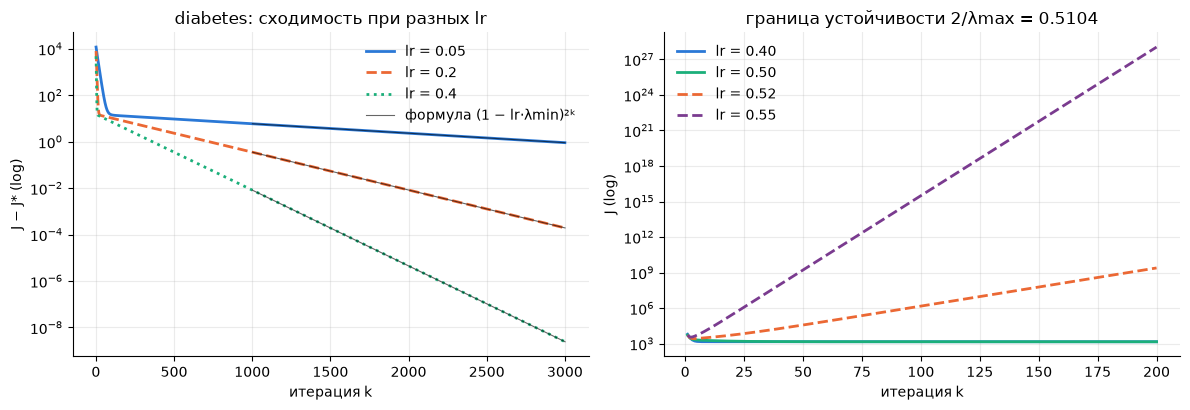

In [15]:
data = REG_DATA["diabetes"]
X_train, y_train = data["X_train"], data["y_train"]
n_train = X_train.shape[0]

# Гессиан цели без штрафа: (1/n)·XaᵀXa, где Xa = [X, 1] (столбец единиц отвечает за intercept)
X_aug = np.hstack([X_train, np.ones((n_train, 1))])
eig = np.linalg.eigvalsh(X_aug.T @ X_aug / n_train)
lam_min, lam_max = eig[0], eig[-1]
lr_limit = 2 / lam_max
j_star = LinearRegression(solver="analytic").fit(X_train, y_train).loss_history_[-1]
print(f"diabetes: lambda_min = {lam_min:.5f}, lambda_max = {lam_max:.5f}, обусловленность = {lam_max / lam_min:.0f}")
print(f"граница устойчивости 2/lambda_max = {lr_limit:.4f};  J* (analytic) = {j_star:.6f}")

LR_LIST = (0.05, 0.2, 0.4)
STEPS = 3000
K = 1000  # где сверяем наблюдаемую скорость с формулой
history = {}
print(f"\n{'lr':>5s} {'J-J* (k=100)':>13s} {'J-J* (k=1000)':>14s} {'J-J* (k=3000)':>14s} {'наблюд. отношение':>18s} {'формула':>10s}")
for lr in LR_LIST:
    model = LinearRegression(solver="gradient", learning_rate=lr, max_iter=STEPS, tol=0.0).fit(X_train, y_train)
    excess = np.array(model.loss_history_) - j_star
    history[lr] = excess
    observed = excess[K + 1] / excess[K]
    predicted = (1 - lr * lam_min) ** 2
    print(f"{lr:5.2f} {excess[99]:13.4e} {excess[K - 1]:14.4e} {excess[STEPS - 1]:14.4e} {observed:18.8f} {predicted:10.8f}")
    assert abs(observed - predicted) < 1e-7

# Расходимость: lr около границы 2/lambda_max и выше неё
DIV_LR = (0.40, 0.50, 0.52, 0.55)
DIV_STEPS = 200
div_history = {}
print(f"\n{'lr':>5s} {'lr*lambda_max':>13s} {'|1-lr*lambda_max|':>18s} {'J (k=1)':>10s} {'J (k=200)':>12s}")
for lr in DIV_LR:
    model = LinearRegression(solver="gradient", learning_rate=lr, max_iter=DIV_STEPS, tol=0.0).fit(X_train, y_train)
    div_history[lr] = np.array(model.loss_history_)
    h = div_history[lr]
    print(f"{lr:5.2f} {lr * lam_max:13.4f} {abs(1 - lr * lam_max):18.4f} {h[0]:10.1f} {h[-1]:12.4e}")
assert div_history[0.40][-1] < div_history[0.40][0] and div_history[0.50][-1] < div_history[0.50][0]
assert div_history[0.52][-1] > 100 * div_history[0.52][0] and div_history[0.55][-1] > 100 * div_history[0.55][0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
colors = {0.05: "#2a78d6", 0.2: "#eb6834", 0.4: "#1baf7a"}
styles = {0.05: "-", 0.2: "--", 0.4: ":"}
for lr in LR_LIST:
    ax1.semilogy(np.arange(1, STEPS + 1), history[lr], color=colors[lr], ls=styles[lr], lw=2, label=f"lr = {lr}")
    k = np.arange(K, STEPS + 1)
    ax1.semilogy(k + 1, history[lr][K] * (1 - lr * lam_min) ** (2 * (k - K)), color="black", lw=0.8, alpha=0.6)
ax1.plot([], [], color="black", lw=0.8, alpha=0.6, label="формула (1 − lr·λmin)²ᵏ")
ax1.set_xlabel("итерация k")
ax1.set_ylabel("J − J* (log)")
ax1.set_title("diabetes: сходимость при разных lr")
ax1.legend(frameon=False)
ax1.grid(alpha=0.25)

dcol = {0.40: "#2a78d6", 0.50: "#1baf7a", 0.52: "#eb6834", 0.55: "#7a3b8f"}
for lr in DIV_LR:
    ax2.semilogy(np.arange(1, DIV_STEPS + 1), div_history[lr], color=dcol[lr], lw=2, ls="-" if lr < lr_limit else "--", label=f"lr = {lr:.2f}")
ax2.set_xlabel("итерация k")
ax2.set_ylabel("J (log)")
ax2.set_title(f"граница устойчивости 2/λmax = {lr_limit:.4f}")
ax2.legend(frameon=False)
ax2.grid(alpha=0.25)
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

### 5.2 Логистика: сырые и стандартизованные признаки

В разделе «Данные» мы стандартизовали признаки (среднее 0, стандартное отклонение 1, по обучающей части). Покажем, зачем это нужно для градиентного спуска.

Гессиан логистической цели не превышает `¼·XaᵀXa/n`. Значит, `L = λmax/4` — константа гладкости, и при `lr < 2/L` значение `J` не возрастает ни на одном шаге. Это условие достаточное, а не необходимое: оценка `¼` достигается только там, где `p = ½`, поэтому чуть выше границы спуск ещё может сходиться (ниже это видно на сырых признаках при `lr = 1e-5`).

У breast_cancer признаки имеют разный масштаб: от сотых долей до тысяч (площадь). Это резко увеличивает `λmax` и обусловленность `λmax/λmin`, а граница `2/L` падает на пять порядков. Ниже одна и та же модель обучается на сырых и на стандартизованных признаках; столбец «шагов вверх» считает шаги, на которых `J` вырос.

признаки              max|x| по признакам  lambda_max  обусловленность        2/L
сырые                   0.030 ..  3432.0   1.629e+06        2.227e+12   4.91e-06
стандартизованные       2.633 ..    11.8       13.17        1.004e+05      0.608

признаки                lr    J (k=1)  J (k=1000)  шагов вверх  acc train  acc test
сырые                1e-06     0.6857      0.4562            0     0.9085    0.9021
сырые                1e-05     0.7544      0.2558           61     0.9178    0.9231
сырые                1e-03      41.14        3.91          527     0.8756    0.8601
сырые                1e-01       4114        1878          538     0.6854    0.6853
сырые                5e-01  2.057e+04   3.046e+04          532     0.4437    0.4266
стандартизованные    1e-06     0.6931      0.6911            0     0.9366    0.9161
стандартизованные    1e-05     0.6931      0.6734            0     0.9366    0.9161
стандартизованные    1e-03     0.6911      0.2459            0     0.9554    0.9510

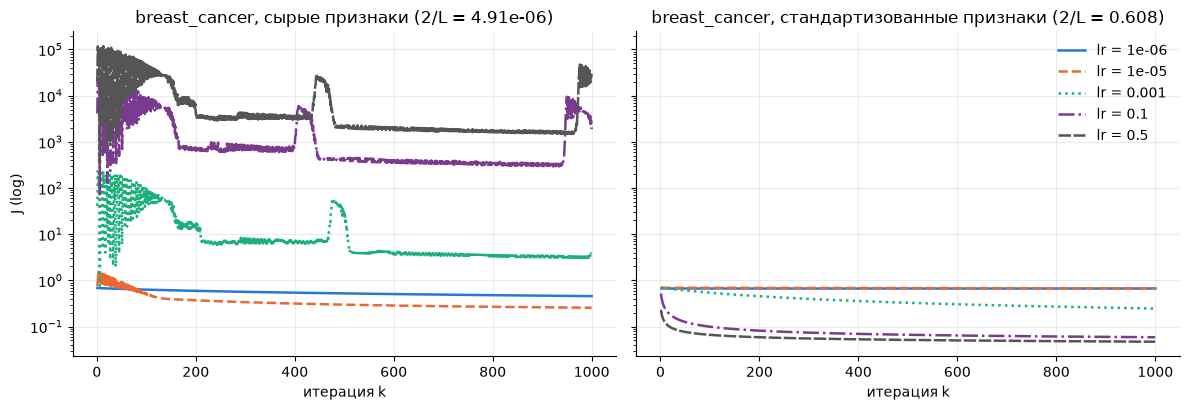

In [16]:
# Те же объекты, что в CLF_DATA["breast_cancer"], но без стандартизации
X_raw_train, X_raw_test, y_train, y_test = train_test_split(
    X_bc, y_bc, test_size=TEST_SIZE, random_state=SEED, stratify=y_bc
)
assert np.array_equal(y_train, CLF_DATA["breast_cancer"]["y_train"])
BC = {
    "сырые": (X_raw_train, X_raw_test),
    "стандартизованные": (CLF_DATA["breast_cancer"]["X_train"], CLF_DATA["breast_cancer"]["X_test"]),
}

# Гладкость логистической цели: гессиан <= (1/4)·XaᵀXa/n, поэтому L = lambda_max/4 и lr < 2/L гарантирует
# невозрастание J. Обусловленность считаем по XaᵀXa/n (множитель 1/4 на отношение не влияет).
bound = {}
print(f"{'признаки':18s} {'max|x| по признакам':>22s} {'lambda_max':>11s} {'обусловленность':>16s} {'2/L':>10s}")
for name, (X_tr, _) in BC.items():
    n_tr = X_tr.shape[0]
    X_aug = np.hstack([X_tr, np.ones((n_tr, 1))])
    eig = np.linalg.eigvalsh(X_aug.T @ X_aug / n_tr)
    bound[name] = 2 / (eig[-1] / 4)
    scale = np.abs(X_tr).max(axis=0)
    print(f"{name:18s} {scale.min():10.3f} ..{scale.max():8.1f} {eig[-1]:11.4g} {eig[-1] / eig[0]:16.3e} {bound[name]:10.3g}")

LR_GRID = (1e-6, 1e-5, 1e-3, 0.1, 0.5)
STEPS = 1000
runs = {}
print(f"\n{'признаки':18s} {'lr':>7s} {'J (k=1)':>10s} {'J (k=1000)':>11s} {'шагов вверх':>12s} {'acc train':>10s} {'acc test':>9s}")
for name, (X_tr, X_te) in BC.items():
    for lr in LR_GRID:
        with np.errstate(all="ignore"):
            model = LogisticRegression(learning_rate=lr, max_iter=STEPS, tol=0.0).fit(X_tr, y_train)
        h = np.array(model.loss_history_)
        ups = int(np.sum(np.diff(h) > 1e-12))
        runs[(name, lr)] = {"h": h, "ups": ups, "acc_test": np.mean(model.predict(X_te) == y_test)}
        print(
            f"{name:18s} {lr:7.0e} {h[0]:10.4g} {h[-1]:11.4g} {ups:12d} "
            f"{np.mean(model.predict(X_tr) == y_train):10.4f} {runs[(name, lr)]['acc_test']:9.4f}"
        )

# lr ниже границы 2/L: J не возрастает ни на одном шаге
assert runs[("сырые", 1e-6)]["ups"] == 0 and 1e-6 < bound["сырые"]
assert runs[("стандартизованные", 0.5)]["ups"] == 0 and 0.5 < bound["стандартизованные"]
# lr выше границы на сырых признаках: J скачет, качество плохое
assert runs[("сырые", 0.1)]["ups"] > 100 and runs[("сырые", 0.1)]["acc_test"] < 0.85
# на стандартизованных те же lr работают
assert runs[("стандартизованные", 0.1)]["acc_test"] > 0.97

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
colors = {1e-6: "#2a78d6", 1e-5: "#eb6834", 1e-3: "#1baf7a", 0.1: "#7a3b8f", 0.5: "#555555"}
styles = {1e-6: "-", 1e-5: "--", 1e-3: ":", 0.1: "-.", 0.5: (0, (5, 1))}
for ax, name in zip(axes, BC):
    for lr in LR_GRID:
        ax.semilogy(np.arange(1, STEPS + 1), runs[(name, lr)]["h"], color=colors[lr], ls=styles[lr], lw=1.8, label=f"lr = {lr:g}")
    ax.set_title(f"breast_cancer, {name} признаки (2/L = {bound[name]:.3g})")
    ax.set_xlabel("итерация k")
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("J (log)")
axes[1].legend(frameon=False, loc="upper right")
fig.tight_layout()
plt.show()

### 5.3 Правило остановки `tol`

Наш спуск останавливается, когда цель уменьшилась меньше чем на `tol` за один шаг: `|J_{k−1} − J_k| < tol`. Это абсолютное условие на `J`, оно не измеряет расстояние до решения.

Связь с этим расстоянием. На больших `k` избыток `e_k = J_k − J*` убывает геометрически: `e_{k+1} = ρ·e_k`, где `ρ = (1 − lr·λmin)²`. Тогда уменьшение за шаг `Δ = e_k − e_{k+1} = e_k·(1 − ρ)`, то есть в момент остановки `e_k = Δ/(1 − ρ) < tol/(1 − ρ)`. Так как `ρ ≈ 1 − 2·lr·λmin`, избыток в `1/(2·lr·λmin)` раз больше `tol`: чем хуже обусловленность и меньше `lr`, тем раньше спуск «ложно» останавливается. Ошибка коэффициентов при этом убывает как корень из избытка.

Поэтому для сравнения с sklearn в разделах 2–4 мы брали `tol = 0.0` и фиксированное число итераций: так итоговая точность определяется только `max_iter`.

In [17]:
data = REG_DATA["diabetes"]
X_train, y_train = data["X_train"], data["y_train"]
n_train = X_train.shape[0]
X_aug = np.hstack([X_train, np.ones((n_train, 1))])
lam_min = np.linalg.eigvalsh(X_aug.T @ X_aug / n_train)[0]
ref = LinearRegression(solver="analytic").fit(X_train, y_train)
j_star = ref.loss_history_[-1]

TOLS = (1e-2, 1e-4, 1e-6, 1e-8)
MAX_ITER = 200_000
print(f"diabetes, J* = {j_star:.6f}, lambda_min = {lam_min:.5f}")
print(f"{'lr':>5s} {'tol':>7s} {'n_iter':>7s} {'J-J*':>10s} {'tol/(1-rho)':>12s} {'отношение':>10s} {'макс |w-w*|':>12s}")
for lr in (0.05, 0.4):
    rho = (1 - lr * lam_min) ** 2  # во сколько раз за шаг убывает J-J* на больших k
    for tol in TOLS:
        model = LinearRegression(solver="gradient", learning_rate=lr, max_iter=MAX_ITER, tol=tol).fit(X_train, y_train)
        excess = model.loss_history_[-1] - j_star
        predicted = tol / (1 - rho)
        print(
            f"{lr:5.2f} {tol:7.0e} {model.n_iter_:7d} {excess:10.3e} {predicted:12.3e} "
            f"{excess / predicted:10.3f} {max_abs_diff(model.coef_, ref.coef_):12.3e}"
        )
        assert model.n_iter_ < MAX_ITER
        assert 0.95 < excess / predicted < 1.05

diabetes, J* = 1453.628882, lambda_min = 0.00938
   lr     tol  n_iter       J-J*  tol/(1-rho)  отношение  макс |w-w*|
 0.05   1e-02     379  1.065e+01    1.066e+01      0.998    3.389e+01
 0.05   1e-04    5288  1.065e-01    1.066e-01      0.998    3.389e+00
 0.05   1e-06   10197  1.065e-03    1.066e-03      0.998    3.389e-01
 0.05   1e-08   15106  1.065e-05    1.066e-05      0.998    3.389e-02
 0.40   1e-02     325  1.320e+00    1.335e+00      0.988    1.193e+01
 0.40   1e-04     938  1.316e-02    1.335e-02      0.986    1.192e+00
 0.40   1e-06    1550  1.322e-04    1.335e-04      0.990    1.194e-01
 0.40   1e-08    2163  1.319e-06    1.335e-06      0.988    1.193e-02


## 6. Выводы и объяснение расхождений

**Что совпало.** При одинаковых данных (`train_test_split`, `random_state=42`, стандартизация по обучающей части) и одинаковой нормировке цели свои модели воспроизводят sklearn:

- линейная регрессия: разность коэффициентов не больше 3.6e-14 для `analytic` и 6.4e-13 для `gradient` (без штрафа и с L2), предсказания и test MSE совпадают до шестого знака;
- логистика без штрафа и с L2: разность коэффициентов от 4e-11 до 2.6e-7, `predict` совпадает на 100 % объектов, `predict_proba` расходится не больше чем на 1.5e-7;
- матрица «штраф × `fit_intercept`» (раздел 4.2): во всех 16 сочетаниях разность коэффициентов не больше 1.6e-8, при `fit_intercept=False` свободный член равен 0.0 у обеих моделей.

**Что расходится, и почему.** Каждое расхождение ниже объяснено и воспроизводится числом в соответствующем разделе.

| Расхождение | Причина | Где видно | Как согласовано |
|---|---|---|---|
| `Ridge` с `alpha` из нашей модели даёт другие коэффициенты | Наша цель `J` делится на `2n`, а в `Ridge` потери не делятся на `n`; нужен `alpha_sk = n·alpha`. Без множителя разность коэффициентов 36.3 (diabetes, alpha = 0.5) | 2.3 | `alpha_sk = n·alpha` |
| `Lasso` | `Lasso` делит потери на `2n`, как и мы | 4.1 | `alpha_sk = alpha`, пересчёта нет |
| `LogisticRegression` | В sklearn штраф стоит при `1/C`, потери суммируются; нужен `C = 1/(n·alpha)` | 3.3, 3.4 | `C = 1/(n·alpha)` |
| Разность коэффициентов в логистике 1e-8…1e-7, а не 1e-14 | Точнее именно наше решение (расстояние до решения Ньютона ≈ 1e-14), а `lbfgs` в sklearn останавливается по `tol` и ошибается на 1e-9…1e-7 | 3.1, 3.3 | Решение Ньютона как эталон |
| `breast_cancer` без штрафа: коэффициенты нельзя сравнивать | Классы линейно разделимы, конечного оптимума нет: веса растут, пока не сработает остановка (наши `‖w‖` 4.8 → 38.9 при росте `max_iter` с 1000 до 100000; у sklearn 451 → 2057 при ужесточении `tol`). Классы совпали на 141 из 143 объектов | 3.2 | Сравниваем `predict`, а не веса |
| L1: у sklearn есть точные нули, у нас нет | Субградиентный спуск не попадает в ноль, а колеблется около него с размахом порядка `lr·alpha`; `saga` использует проксимальный шаг и обнуляет точно. `dJ` относительно `saga` неотрицателен и уменьшается вместе с `lr` | 3.4, 4.1 | Сравниваем цель `J` и классы |
| Сырые признаки: спуск не работает | Разный масштаб признаков даёт огромную обусловленность (2.2e12 против 1.0e5) и границу `2/L` = 4.9e-6 против 0.608 | 5.2 | Стандартизация по train |
| Ранняя остановка по `tol` | Остановка по уменьшению `J` оставляет избыток `J − J*` порядка `tol/(1 − ρ)`, в сотни и тысячи раз больше `tol` | 5.3 | `tol = 0.0` и большой `max_iter` |

**Ограничения нашей реализации** (для README):

- остановка по абсолютному изменению цели, а не по норме градиента или расстоянию до решения (5.3);
- L1 без точных нулей;
- `random_state` не используется (разбиение и инициализация детерминированы);
- на разделимых данных без штрафа веса не ограничены.

**Воспроизводимость.** Версии библиотек напечатаны в начале ноутбука; все случайные шаги зафиксированы `SEED = 42`, а `saga` получает `random_state=SEED`.